In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
from collections.abc import Iterable
import geopandas as gpd
import shapely.geometry as geom
import cmcrameri as cmc

import math
import random
import json

from weavingspace import TileUnit, Tiling
import string
import itertools

In [2]:
TILE_IDS = [
  *string.ascii_lowercase,
  *["".join(x) for x in itertools.product(
    string.ascii_lowercase, string.ascii_lowercase)]
]


EPS = 1e-4

r3 = math.sqrt(3) / 2
x_base = 1, r3, 0.5, 0
y_base = 0, 0.5, r3, 1

# // Xbase[4] = -0.5;   Ybase[4] = r3;
# // Xbase[5] = -r3;    Ybase[5] = 0.5;
# // Xbase[6] = -1;     Ybase[6] = 0;
# // Xbase[7] = -r3;    Ybase[7] = -0.5;
# // Xbase[8] = -0.5;   Ybase[8] = -r3;
# // Xbase[9] = 0;     Ybase[9] = -1;
# // Xbase[10] = 0.5;   Ybase[10] = -r3;
# // Xbase[11] = r3;    Ybase[11] = -0.5;

base_change = (
  ( 1,  0,  0,  0),
  ( 0,  1,  0,  0),
  ( 0,  0,  1,  0),
  ( 0,  0,  0,  1),
  (-1,  0,  1,  0),
  ( 0, -1,  0,  1),
  (-1,  0,  0,  0),
  ( 0, -1,  0,  0),
  ( 0,  0, -1,  0),
  ( 0,  0,  0, -1),
  ( 1,  0, -1,  0),
  ( 0,  1,  0, -1)
)

vertex_type = {
  (3, 12, 12): 0,
  (4, 6, 12): 1,
  (6, 4, 12): 1,
  (4, 4, 8): 2,
  (6, 6, 6): 3,
  (3, 3, 4, 12): 4,
  (4, 3, 3, 12): 4,
  (3, 4, 3, 12): 5,
  (4, 4, 3, 6): 6,
  (3, 4, 4, 6): 6,
  (4, 3, 4, 6): 7,
  (3, 3, 6, 6): 8,
  (3, 6, 3, 6): 9,
  (4, 4, 4, 4): 10,
  (3, 3, 3, 4, 4): 11,
  (3, 3, 4, 3, 4): 12,
  (3, 3, 3, 3, 6): 13,
  (3, 3, 3, 3, 3, 3): 14
}


In [3]:
with open("tiles-2.json", "r") as file:
    Symbols1 = json.load(file)
with open("tiles.json", "r") as file:
    Symbols2 = json.load(file)
Symbols = Symbols1 | Symbols2

In [4]:
def change_base(a, t1, t2):
  det = t1[0] * t2[1] - t1[1] * t2[0]
  d1 = a[0] * t2[1] - a[1] * t2[0]
  d2 = t1[0] * a[1] - t1[1] * a[0]
  return d1 / det, d2 / det

def circle_list(lst):
  return [lst[-1], *lst[:-1]]

def class_vertex(symbol):
  new_symbol = symbol
  count = 0
  if len(new_symbol) < 3: return -1
  while new_symbol not in vertex_type and count < len(symbol):
    new_symbol = tuple(circle_list(new_symbol))
    count = count + 1
  return vertex_type[new_symbol]

def base_to_point(seed):
  return sum(s * x for s, x in zip(seed, x_base)), \
	       sum(s * y for s, y in zip(seed, y_base))

def patch_build(points, t1, t2, n0, n1):
	patch = []
	for k1 in range(n0, n1 + 1):
		for k2 in range(n0, n1 + 1):
			for point in points:
				t = tuple(k1 * u + k2 * v for u, v in zip(t1, t2))
				patch.append(tuple(x + y for x, y in zip(point, t)))
	return patch

def patch_hash(points, t1, t2, n0, n1):
	patch = {}
	for k1 in range(n0, n1 + 1):
		for k2 in range(n0, n1 + 1):
			for point in points:
				t = tuple(k1 * u + k2 * v for u, v in zip(t1, t2))
				patch[tuple(round(x + y, 6) for x, y in zip(point, t))] = 1
	return patch

def star_build(point, patch):
	star = []
	for k in range(12):
		candidate = tuple(round(x + dx, 6) for x, dx in zip(point, base_change[k]))
		if candidate in patch:
			star.append(k)
	return star
	
def omega_to_poly(k):
	k = abs(k)
	n = 0
	if k == 2:
		n = 3
	elif k == 3:
		n = 4
	elif k == 4:
		n = 6
	elif k == 5:
		n = 12
	elif k >= 6:
		n = omega_to_poly(12 - k)
	else:
		return None
	return n

def get_face(w, i, n):
	J = math.floor(12 / n)
	centre = [0, 0, 0, 0]
	p = w
	face = [w]
	for j in range(0, 12, J):
		p = [x + dx for x, dx in zip(p, base_change[(i + j) % 12])]
		centre = [c + x for c, x in zip(centre, p)]
		face.append(p)
	return [6 * c / n for c in centre], face[:-1]

def star_to_faces(star, centre):
	centroids, faces = [], []
	for left, right in zip(star, [*star[1:], star[0]]):
		n = omega_to_poly((right - left) % 12)
		if n > 0:
			result = get_face(centre, left, n)
			centroids.append(result[0])
			faces.append(result[1])
	return centroids, faces

def star_class(star, centre):
	symbol = []
	for left, right in zip(star, [*star[1:], star[0]]):
		n = omega_to_poly((right - left) % 12)
		symbol.append(n)
	return class_vertex(tuple(symbol))

def w_region_test(p, t1, t2):
	U = change_base(base_to_point(p), base_to_point(t1), base_to_point(t2))
	return ((U[0] >= -EPS) and (U[0] < 1 - EPS) and 
					(U[1] >= -EPS) and (U[1] < 1 - EPS))

def mesh_build(tile):
	mesh1 = ArchMesh()
	if tile not in ["t1002", "J"]:
		ts1 = Symbols[tile]["T1"]
		ts2 = Symbols[tile]["T2"]
		seed = Symbols[tile]["Seed"]
		face_points = patch_build(seed, ts1, ts2, 0, 1)
		patch = patch_hash(seed, ts1, ts2, -1, 2)
		faces = []
		centroids = []
		centroids_hash = {}
		for face_point in face_points:
			these_centroids, these_faces = \
				star_to_faces(star_build(face_point, patch), face_point)
			for face, centroid in zip(these_faces, these_centroids):
				hash = tuple(int(x) for x in centroid)
				if w_region_test([c / 6 for c in centroid], ts1, ts2) and \
					hash not in centroids_hash:
						centroids_hash[hash] = 1
						faces.append(face)
						centroids.append(centroid)
		mesh1.tvec1 = ts1
		mesh1.tvec2 = ts2
		mesh1.vertex_set = seed
		mesh1.poly_sets = faces
		mesh1.dual_points = centroids
		mesh1.vertex_types = [star_class(star_build(s, patch), s) for s in seed]
	else:
		ct = math.sqrt(2) / 2
		mesh1.tvec1 = [1 + ct, 0, 0, 1 + ct]
		mesh1.tvec2 = [3.4142, 0, 0, 0]
		mesh1.vertex_set = [
			[0, 0, 0, 0], [1, 0, 0, 0], [1, 0, 0, 1], [0, 0, 0, 1]]
		mesh1.poly_sets = [
			[[0, 0, 0, 0], [1, 0, 0, 0], [1, 0, 0, 1], [0, 0, 0, 1]],
			[[1, 0, 0, 0], [1, 0, 0, 1], [1 + ct, 0, 0, 1 + ct], 
			 [2 + ct, 0, 0, 1 + ct], [2 + 2 * ct, 0, 0, 1], [2 + 2 * ct, 0, 0, 0],
			 [2 + ct, 0, 0, -ct], [1 + ct, 0, 0, -ct]]]
		mesh1.dual_points = [[3, 0, 0, 3], [9 + 6 * ct, 0, 0, 3]]
		mesh1.vertex_types = [2, 2, 2, 2]
	return mesh1


class ArchMesh:
  def __init__(self):
    self.tvec1 = tuple()
    self.tvec2 = tuple()
    self.vertex_set = []
    self.poly_sets = []
    self.dual_points = []
    self.origin = tuple()
    self.vertex_types = {}


In [5]:
rect = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(
    [geom.Polygon([(-1500, -900), (-1500, 900), (1500, 900), (1500, -900)])]),
  crs = 3857, data = {"x" : [1]}
)

In [27]:
def plot_tiling(code, region = rect):
  mesh = mesh_build(code)
  n = len(mesh.poly_sets)
  polys = []
  for points in mesh.poly_sets:
    polys.append(geom.Polygon([base_to_point(xy) for xy in points]))
  t = TileUnit()
  t.tiles = gpd.GeoDataFrame(
    geometry = gpd.GeoSeries(polys), crs = 3857,
    data = {"tile_id": TILE_IDS[:len(polys)]} 
  )
  t.setup_vectors(base_to_point(mesh.tvec1), base_to_point(mesh.tvec2))
  t.prototile = t.get_prototile_from_vectors()
  t._setup_regularised_prototile(True)
  t = t.transform_scale(50, 50)
  tiling = Tiling(t, rect)
  fig = plt.figure(figsize = (10, 6), layout = "constrained")
  ax = fig.add_subplot(111)
  tiling.tiles.plot(ax = ax,
    column = "tile_id", ec = "w", lw = 0.5, cmap = "cmc.romaO")
  ax.set_title(f"{code} ({n=})")
  ax.set_axis_off()
  ax.set_xlim((-1200, 1200))
  ax.set_ylim((-720, 720))

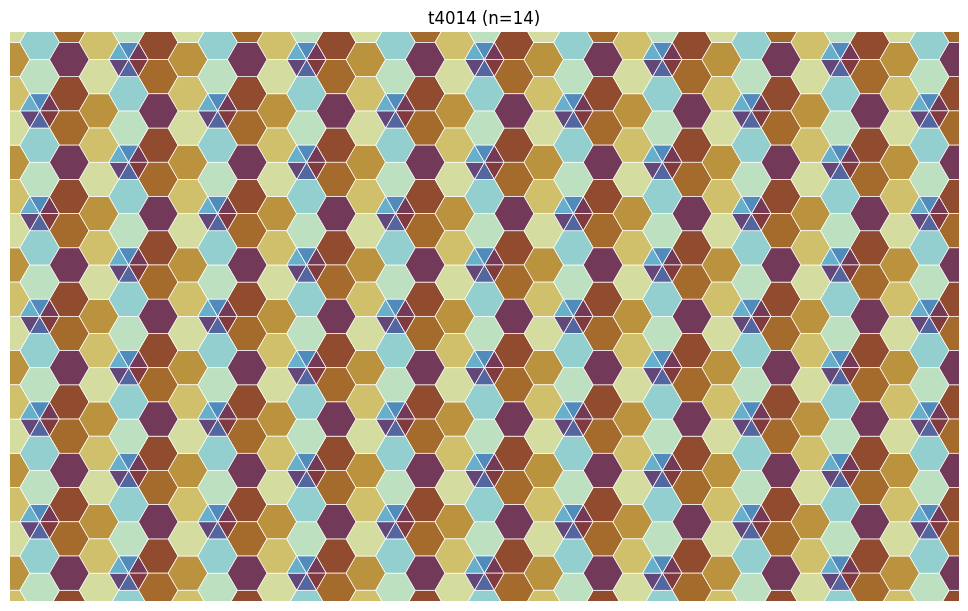

In [53]:
plot_tiling(random.choice(list(Symbols.keys())))